<a href="https://colab.research.google.com/github/anshikaguptacs24-del/BIO_INSPIRED_LAB/blob/main/Cuckoo_search_Function_optimiztion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best solution: [-6.24041328e-05 -7.29401993e-05]
Minimum function value: 1.8280934810377403e-06


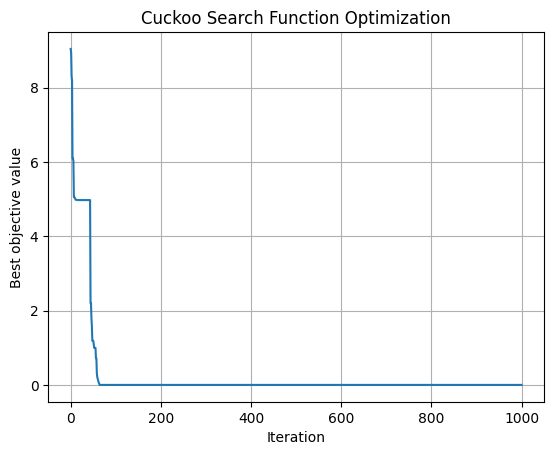

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import math

# 1. Objective function: Rastrigin
def objective(x):
    d = len(x)
    return 10 * d + np.sum(
        x**2 - 10 * np.cos(2 * np.pi * x)
    )

# 2. Generate a Levy-flight random step
def levy_flight(dim, beta=1.5):
    sigma = (
        math.gamma(1 + beta) * np.sin(np.pi * beta / 2)
        / (
            math.gamma((1 + beta) / 2)
            * beta * 2**((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma, dim)
    v = np.random.normal(0, 1, dim)

    return u / (np.abs(v)**(1 / beta) + 1e-12)

# 3. Cuckoo Search parameters
np.random.seed(42)

n = 25
pa = 0.25
iterations = 1000
dim = 2
alpha = 0.01

lower, upper = -5.12, 5.12

# 4. Initialize random nests
nests = np.random.uniform(
    lower, upper, (n, dim)
)

fitness = np.array([
    objective(x) for x in nests
])

best_index = np.argmin(fitness)
best_solution = nests[best_index].copy()
best_value = fitness[best_index]

history = [best_value]

# 5. Main Cuckoo Search loop
for t in range(iterations):

    for i in range(n):

        # Generate a new candidate using Levy flight
        step = levy_flight(dim)
        candidate = nests[i] + alpha * step

        # Enforce search boundaries
        candidate = np.clip(
            candidate, lower, upper
        )

        new_value = objective(candidate)

        # Select a random nest
        j = np.random.randint(n)

        # Replace only if the candidate is better
        if new_value < fitness[j]:
            nests[j] = candidate
            fitness[j] = new_value

    # Abandon the worst 25% of nests
    count = max(1, round(pa * n))
    worst = np.argsort(fitness)[-count:]

    nests[worst] = np.random.uniform(
        lower, upper, (count, dim)
    )

    fitness[worst] = np.array([
        objective(x) for x in nests[worst]
    ])

    # Update the global best
    index = np.argmin(fitness)

    if fitness[index] < best_value:
        best_value = fitness[index]
        best_solution = nests[index].copy()

    history.append(best_value)

# 6. Display results
print("Best solution:", best_solution)
print("Minimum function value:", best_value)

# 7. Plot convergence
plt.plot(history)
plt.xlabel("Iteration")
plt.ylabel("Best objective value")
plt.title("Cuckoo Search Function Optimization")
plt.grid(True)
plt.show()
